In [ ]:
# ============================================================
# PHASE 2 — SUBTERRANEAN THERMAL RESERVOIR MAPPING (VAR2)
# Initial Setup + Load Training Data
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. LOAD VAR2 TRAINING DATA
# ------------------------------------------------------------

df2 = pd.read_csv('/content/IMT2024080_train_var2(in).csv')

print("Training data shape:", df2.shape)
print("Columns:", df2.columns.tolist())

display(df2.head())


# ------------------------------------------------------------
# 2. SEPARATE INPUT FEATURES AND TARGET
# ------------------------------------------------------------

X2 = df2.drop(columns='y')
y2 = df2['y']

print("\nX shape:", X2.shape)
print("y shape:", y2.shape)


# ------------------------------------------------------------
# 3. BASIC SANITY CHECKS
# ------------------------------------------------------------

print("\nMissing values:")
print(df2.isnull().sum())

print("\nDataset statistics:")
display(df2.describe())


# ------------------------------------------------------------
# 4. SET UP SAME 5-FOLD CROSS VALIDATION
# ------------------------------------------------------------

kf2 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("\n5-fold CV ready.")

Training data shape: (1000, 4)
Columns: ['x1', 'x2', 'x3', 'y']


,x1,x2,x3,y
0,-0.045821,-0.119053,-0.068501,0.944491
1,-0.333584,1.000000,0.982724,14.718417
2,1.000000,0.104518,-0.948591,9.603999
3,-0.394197,-0.039673,-0.698174,0.155587
4,1.000000,0.827298,-0.489964,9.819070



X shape: (1000, 3)
y shape: (1000,)

Missing values:
x1    0
x2    0
x3    0
y     0
dtype: int64

Dataset statistics:


,x1,x2,x3,y
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.000955,-0.014560,0.042773,2.460914
std,0.692607,0.681884,0.670309,6.781684
min,-1.000000,-1.000000,-1.000000,-30.141976
25%,-0.590364,-0.622944,-0.495070,-0.570387
50%,-0.007813,-0.037376,0.064716,1.240816
75%,0.608551,0.543320,0.624578,5.460330
max,1.000000,1.000000,1.000000,39.026721



5-fold CV ready.


In [ ]:
# ============================================================
# VAR2 — OLS POLYNOMIAL REGRESSION
# Degrees 1 to 20 using 5-Fold Cross Validation
# ============================================================

degrees = range(1, 21)

ols2_results = []

for degree in degrees:

    fold_mse = []
    fold_r2 = []

    for train_idx, val_idx in kf2.split(X2):

        # Split this fold
        X_train = X2.iloc[train_idx]
        X_val = X2.iloc[val_idx]

        y_train = y2.iloc[train_idx]
        y_val = y2.iloc[val_idx]

        # 1. Generate polynomial features
        poly = PolynomialFeatures(
            degree=degree,
            include_bias=False
        )

        X_train_poly = poly.fit_transform(X_train)
        X_val_poly = poly.transform(X_val)

        # 2. Standardize features
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train_poly)
        X_val_scaled = scaler.transform(X_val_poly)

        # 3. Train OLS model
        model = LinearRegression()
        model.fit(X_train_scaled, y_train)

        # 4. Predict validation fold
        y_pred = model.predict(X_val_scaled)

        # 5. Evaluate
        fold_mse.append(
            mean_squared_error(y_val, y_pred)
        )

        fold_r2.append(
            r2_score(y_val, y_pred)
        )

    # Average over the 5 folds
    ols2_results.append({
        'degree': degree,
        'mse': np.mean(fold_mse),
        'r2': np.mean(fold_r2)
    })


# Convert to DataFrame
ols2_df = pd.DataFrame(ols2_results)

display(ols2_df)


# ============================================================
# FIND BEST DEGREE
# ============================================================

best_ols2_mse = ols2_df.loc[
    ols2_df['mse'].idxmin()
]

best_ols2_r2 = ols2_df.loc[
    ols2_df['r2'].idxmax()
]

print("\nBest OLS by MSE:")
print(best_ols2_mse)

print("\nBest OLS by R²:")
print(best_ols2_r2)

,degree,mse,r2
0,1,3.455482e+01,2.480401e-01
1,2,2.255110e+01,5.098431e-01
2,3,1.087639e+01,7.605452e-01
3,4,3.415351e+00,9.251554e-01
4,5,1.394536e+00,9.691345e-01
5,6,5.737285e-01,9.872540e-01
6,7,3.506754e-01,9.922105e-01
7,8,2.831570e-01,9.936972e-01
8,9,2.947160e-01,9.934522e-01
9,10,3.724618e-01,9.916672e-01



Best OLS by MSE:
degree    8.000000
mse       0.283157
r2        0.993697
Name: 7, dtype: float64

Best OLS by R²:
degree    8.000000
mse       0.283157
r2        0.993697
Name: 7, dtype: float64


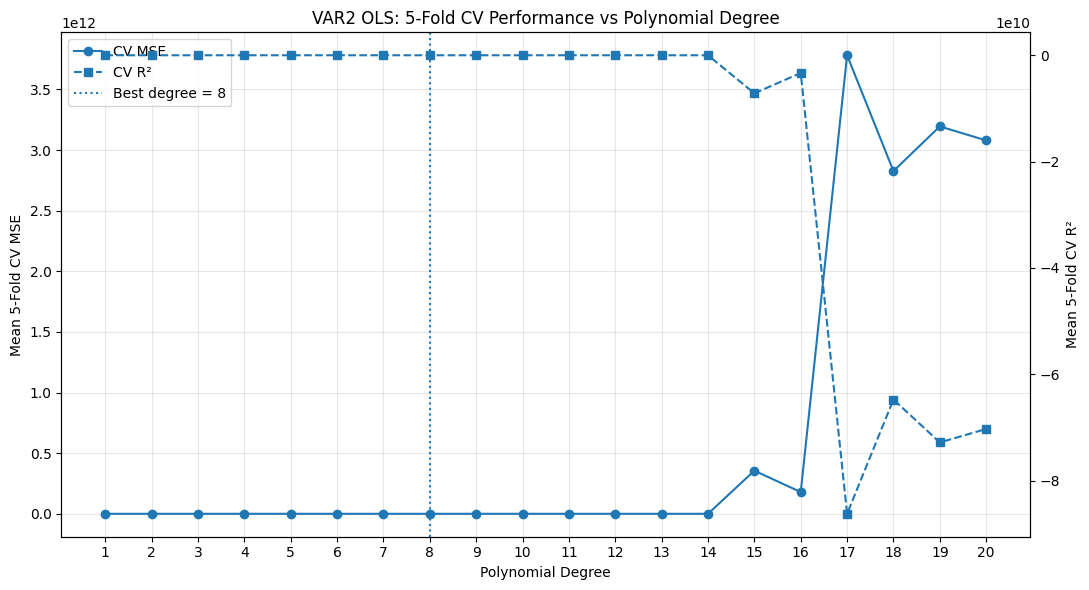

In [ ]:
# ============================================================
# OLS DEGREE vs MSE AND R²
# ============================================================

fig, ax1 = plt.subplots(figsize=(11, 6))

# MSE
line1 = ax1.plot(
    ols2_df['degree'],
    ols2_df['mse'],
    'o-',
    label='CV MSE'
)

ax1.set_xlabel('Polynomial Degree')
ax1.set_ylabel('Mean 5-Fold CV MSE')
ax1.set_xticks(range(1, 21))

# R²
ax2 = ax1.twinx()

line2 = ax2.plot(
    ols2_df['degree'],
    ols2_df['r2'],
    's--',
    label='CV R²'
)

ax2.set_ylabel('Mean 5-Fold CV R²')

# Mark best degree
best_degree = int(best_ols2_mse['degree'])

best_line = ax1.axvline(
    best_degree,
    linestyle=':',
    label=f'Best degree = {best_degree}'
)

# Combined legend
lines = line1 + line2 + [best_line]
labels = [line.get_label() for line in lines]

ax1.legend(lines, labels)
ax1.grid(alpha=0.3)

plt.title('VAR2 OLS: 5-Fold CV Performance vs Polynomial Degree')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# VAR2 — RIDGE POLYNOMIAL REGRESSION
# Degrees 1-20 + Lambda Search + 5-Fold CV
# ============================================================

degrees = range(1, 21)
lambdas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

ridge2_results = []

for degree in degrees:

    for lam in lambdas:

        fold_mse = []
        fold_r2 = []

        for train_idx, val_idx in kf2.split(X2):

            # Split current fold
            X_train = X2.iloc[train_idx]
            X_val = X2.iloc[val_idx]

            y_train = y2.iloc[train_idx]
            y_val = y2.iloc[val_idx]

            # 1. Polynomial features
            poly = PolynomialFeatures(
                degree=degree,
                include_bias=False
            )

            X_train_poly = poly.fit_transform(X_train)
            X_val_poly = poly.transform(X_val)

            # 2. Standardize
            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train_poly)
            X_val_scaled = scaler.transform(X_val_poly)

            # 3. Ridge regression
            model = Ridge(alpha=lam)
            model.fit(X_train_scaled, y_train)

            # 4. Validation prediction
            y_pred = model.predict(X_val_scaled)

            # 5. Metrics
            fold_mse.append(
                mean_squared_error(y_val, y_pred)
            )

            fold_r2.append(
                r2_score(y_val, y_pred)
            )

        # Average across 5 folds
        ridge2_results.append({
            'degree': degree,
            'lambda': lam,
            'mse': np.mean(fold_mse),
            'r2': np.mean(fold_r2)
        })


# ============================================================
# RESULTS
# ============================================================

ridge2_df = pd.DataFrame(ridge2_results)

display(ridge2_df)


# Best according to MSE
best_ridge2_mse = ridge2_df.loc[
    ridge2_df['mse'].idxmin()
]

# Best according to R²
best_ridge2_r2 = ridge2_df.loc[
    ridge2_df['r2'].idxmax()
]

print("\nBest Ridge by MSE:")
print(best_ridge2_mse)

print("\nBest Ridge by R²:")
print(best_ridge2_r2)

,degree,lambda,mse,r2
0,1,0.0001,34.554820,0.248040
1,1,0.0010,34.554820,0.248040
2,1,0.0100,34.554818,0.248040
3,1,0.1000,34.554796,0.248041
4,1,1.0000,34.554598,0.248048
...,...,...,...,...
135,20,0.0100,0.892751,0.980035
136,20,0.1000,0.474952,0.989240
137,20,1.0000,0.315490,0.992984
138,20,10.0000,0.291464,0.993554



Best Ridge by MSE:
degree    11.000000
lambda     1.000000
mse        0.253926
r2         0.994352
Name: 74, dtype: float64

Best Ridge by R²:
degree    11.000000
lambda     1.000000
mse        0.253926
r2         0.994352
Name: 74, dtype: float64


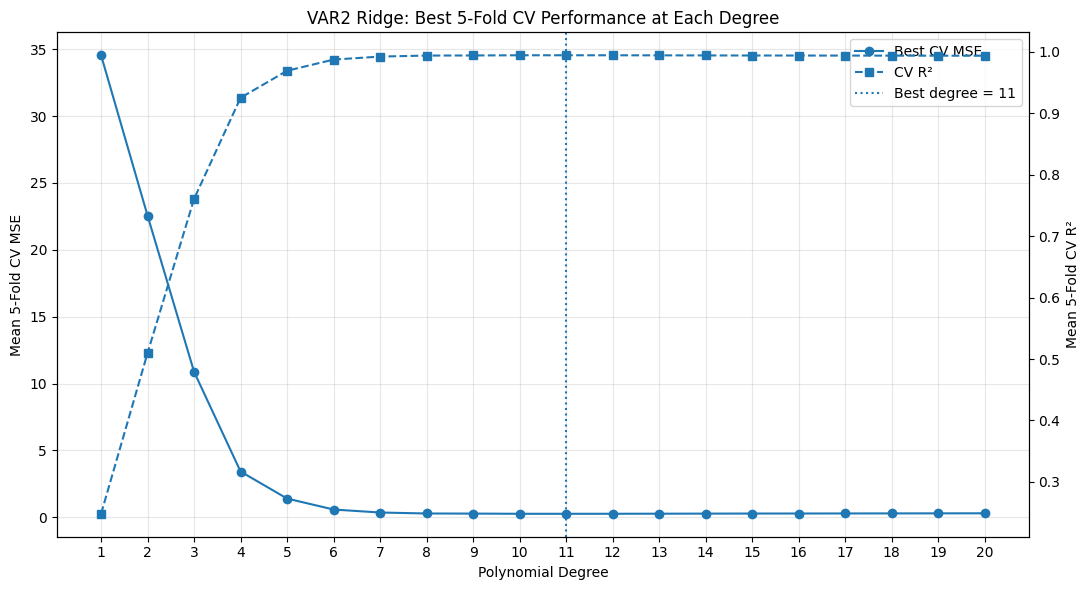


Best lambda at each degree:


,degree,lambda,mse,r2
5,1,10.00,34.554279,0.248083
11,2,1.00,22.550896,0.509865
18,3,1.00,10.874829,0.760623
24,4,0.10,3.415002,0.925165
31,5,0.10,1.394354,0.969146
38,6,0.10,0.573356,0.987288
44,7,0.01,0.350233,0.992221
52,8,0.10,0.276914,0.993832
59,9,0.10,0.269092,0.994018
67,10,1.00,0.254561,0.994333


In [ ]:
# ============================================================
# BEST RIDGE RESULT AT EACH DEGREE
# ============================================================

best_per_degree = (
    ridge2_df
    .loc[ridge2_df.groupby('degree')['mse'].idxmin()]
    .sort_values('degree')
)

fig, ax1 = plt.subplots(figsize=(11, 6))

# MSE
line1 = ax1.plot(
    best_per_degree['degree'],
    best_per_degree['mse'],
    'o-',
    label='Best CV MSE'
)

ax1.set_xlabel('Polynomial Degree')
ax1.set_ylabel('Mean 5-Fold CV MSE')
ax1.set_xticks(range(1, 21))

# R²
ax2 = ax1.twinx()

line2 = ax2.plot(
    best_per_degree['degree'],
    best_per_degree['r2'],
    's--',
    label='CV R²'
)

ax2.set_ylabel('Mean 5-Fold CV R²')

# Best overall
best_degree = int(best_ridge2_mse['degree'])

best_line = ax1.axvline(
    best_degree,
    linestyle=':',
    label=f'Best degree = {best_degree}'
)

lines = line1 + line2 + [best_line]
labels = [line.get_label() for line in lines]

ax1.legend(lines, labels)
ax1.grid(alpha=0.3)

plt.title(
    'VAR2 Ridge: Best 5-Fold CV Performance at Each Degree'
)

plt.tight_layout()
plt.show()


print("\nBest lambda at each degree:")
display(
    best_per_degree[
        ['degree', 'lambda', 'mse', 'r2']
    ]
)

In [ ]:
# ============================================================
# VAR2 — LASSO POLYNOMIAL REGRESSION
# Degrees 1-20 + Lambda Search + 5-Fold CV
# ============================================================

degrees = range(1, 21)
lambdas = [0.01, 0.1, 1, 10, 100]

lasso2_results = []

for degree in degrees:

    for lam in lambdas:

        fold_mse = []
        fold_r2 = []

        for train_idx, val_idx in kf2.split(X2):

            X_train = X2.iloc[train_idx]
            X_val = X2.iloc[val_idx]

            y_train = y2.iloc[train_idx]
            y_val = y2.iloc[val_idx]

            # Polynomial features
            poly = PolynomialFeatures(
                degree=degree,
                include_bias=False
            )

            X_train_poly = poly.fit_transform(X_train)
            X_val_poly = poly.transform(X_val)

            # Standardize using ONLY current training fold
            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train_poly)
            X_val_scaled = scaler.transform(X_val_poly)

            # LASSO
            model = Lasso(
                alpha=lam,
                max_iter=30000,
                selection='random',
                random_state=42
            )

            model.fit(X_train_scaled, y_train)

            # Validation predictions
            y_pred = model.predict(X_val_scaled)

            fold_mse.append(
                mean_squared_error(y_val, y_pred)
            )

            fold_r2.append(
                r2_score(y_val, y_pred)
            )

        lasso2_results.append({
            'degree': degree,
            'lambda': lam,
            'mse': np.mean(fold_mse),
            'r2': np.mean(fold_r2)
        })


# Results
lasso2_df = pd.DataFrame(lasso2_results)

display(lasso2_df)


# Best by MSE
best_lasso2_mse = lasso2_df.loc[
    lasso2_df['mse'].idxmin()
]

# Best by R²
best_lasso2_r2 = lasso2_df.loc[
    lasso2_df['r2'].idxmax()
]

print("\nBest LASSO by MSE:")
print(best_lasso2_mse)

print("\nBest LASSO by R²:")
print(best_lasso2_r2)

,degree,lambda,mse,r2
0,1,0.01,34.554982,0.248015
1,1,0.10,34.557438,0.247826
2,1,1.00,36.479840,0.205636
3,1,10.00,46.034111,-0.005262
4,1,100.00,46.034111,-0.005262
...,...,...,...,...
95,20,0.01,0.370491,0.991675
96,20,0.10,1.370724,0.969198
97,20,1.00,15.433816,0.662514
98,20,10.00,46.034111,-0.005262



Best LASSO by MSE:
degree    14.000000
lambda     0.010000
mse        0.359380
r2         0.991928
Name: 65, dtype: float64

Best LASSO by R²:
degree    14.000000
lambda     0.010000
mse        0.359380
r2         0.991928
Name: 65, dtype: float64


=== FINE LASSO SEARCH — DEGREE 11 ===

Best by MSE:
lambda    0.000700
mse       0.254273
r2        0.994335
Name: 5, dtype: float64

Best by R²:
lambda    0.000700
mse       0.254273
r2        0.994335
Name: 5, dtype: float64


,lambda,mse,r2
0,0.0002,0.264852,0.994116
1,0.0003,0.260437,0.994209
2,0.0004,0.257586,0.994269
3,0.0005,0.255783,0.994306
4,0.0006,0.254759,0.994326
5,0.0007,0.254273,0.994335
6,0.0008,0.254364,0.994332
7,0.0009,0.254514,0.994328
8,0.0010,0.254735,0.994322
9,0.0011,0.255593,0.994303


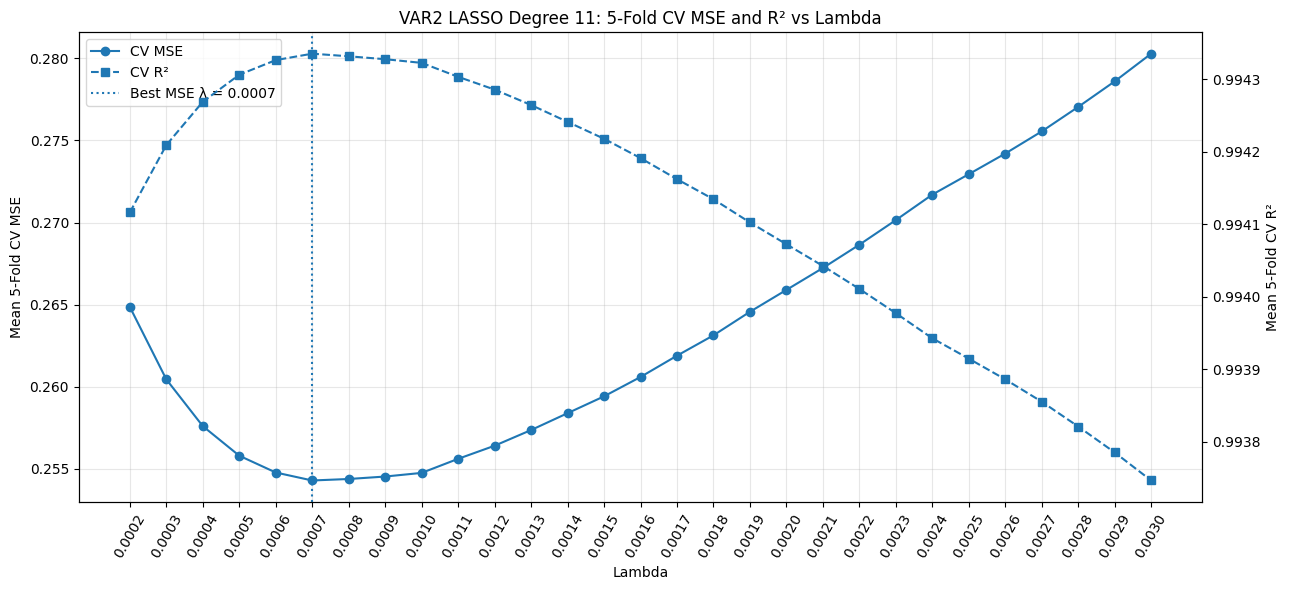

In [ ]:
# ============================================================
# VAR2 — FINE LASSO SEARCH
# Degree fixed at 11
# Lambda: 0.0002 -> 0.0030, step 0.0001
# 5-Fold Cross Validation
# ============================================================

degree = 11

lambdas_fine = np.arange(0.0002, 0.00301, 0.0001)

fine_lasso_results = []

for lam in lambdas_fine:

    fold_mse = []
    fold_r2 = []

    for train_idx, val_idx in kf2.split(X2):

        # Split current fold
        X_train = X2.iloc[train_idx]
        X_val = X2.iloc[val_idx]

        y_train = y2.iloc[train_idx]
        y_val = y2.iloc[val_idx]

        # 1. Polynomial features
        poly = PolynomialFeatures(
            degree=degree,
            include_bias=False
        )

        X_train_poly = poly.fit_transform(X_train)
        X_val_poly = poly.transform(X_val)

        # 2. Standardize using training fold only
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train_poly)
        X_val_scaled = scaler.transform(X_val_poly)

        # 3. LASSO
        # Default selection='cyclic' for deterministic final comparison
        model = Lasso(
            alpha=lam,
            max_iter=50000
        )

        model.fit(X_train_scaled, y_train)

        # 4. Predict validation fold
        y_pred = model.predict(X_val_scaled)

        # 5. Evaluate
        fold_mse.append(
            mean_squared_error(y_val, y_pred)
        )

        fold_r2.append(
            r2_score(y_val, y_pred)
        )

    fine_lasso_results.append({
        'lambda': lam,
        'mse': np.mean(fold_mse),
        'r2': np.mean(fold_r2)
    })


# ============================================================
# RESULTS
# ============================================================

fine_lasso_df = pd.DataFrame(fine_lasso_results)

best_fine_lasso_mse = fine_lasso_df.loc[
    fine_lasso_df['mse'].idxmin()
]

best_fine_lasso_r2 = fine_lasso_df.loc[
    fine_lasso_df['r2'].idxmax()
]

print("=== FINE LASSO SEARCH — DEGREE 11 ===")

print("\nBest by MSE:")
print(best_fine_lasso_mse)

print("\nBest by R²:")
print(best_fine_lasso_r2)

display(fine_lasso_df)


# ============================================================
# MSE + R² OVERLAID PLOT
# ============================================================

fig, ax1 = plt.subplots(figsize=(13, 6))

# MSE
line1 = ax1.plot(
    fine_lasso_df['lambda'],
    fine_lasso_df['mse'],
    'o-',
    label='CV MSE'
)

ax1.set_xlabel('Lambda')
ax1.set_ylabel('Mean 5-Fold CV MSE')


# R² on second axis
ax2 = ax1.twinx()

line2 = ax2.plot(
    fine_lasso_df['lambda'],
    fine_lasso_df['r2'],
    's--',
    label='CV R²'
)

ax2.set_ylabel('Mean 5-Fold CV R²')


# Best MSE lambda
best_lambda = best_fine_lasso_mse['lambda']

best_line = ax1.axvline(
    best_lambda,
    linestyle=':',
    label=f'Best MSE λ = {best_lambda:.4f}'
)


# Show every lambda tested
ax1.set_xticks(fine_lasso_df['lambda'])

ax1.set_xticklabels(
    [f'{x:.4f}' for x in fine_lasso_df['lambda']],
    rotation=60
)


# Combined legend
lines = line1 + line2 + [best_line]
labels = [line.get_label() for line in lines]

ax1.legend(lines, labels, loc='best')

ax1.grid(alpha=0.3)

plt.title(
    'VAR2 LASSO Degree 11: '
    '5-Fold CV MSE and R² vs Lambda'
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# VAR2 — CLEAN LOCAL LASSO SEARCH
# Degrees: 10, 11, 12
# Lambda: 0.0003 to 0.0015
# Fixed solver settings for fair comparison
# ============================================================

local_degrees = [10, 11, 12]

local_lambdas = np.arange(0.0003, 0.00151, 0.0001)

lasso_local_results = []

for degree in local_degrees:

    for lam in local_lambdas:

        fold_mse = []
        fold_r2 = []
        fold_iterations = []

        for train_idx, val_idx in kf2.split(X2):

            X_train = X2.iloc[train_idx]
            X_val = X2.iloc[val_idx]

            y_train = y2.iloc[train_idx]
            y_val = y2.iloc[val_idx]

            # ----------------------------------------
            # 1. Polynomial features
            # ----------------------------------------
            poly = PolynomialFeatures(
                degree=degree,
                include_bias=False
            )

            X_train_poly = poly.fit_transform(X_train)
            X_val_poly = poly.transform(X_val)

            # ----------------------------------------
            # 2. Standardization
            # Fit ONLY on training fold
            # ----------------------------------------
            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train_poly)
            X_val_scaled = scaler.transform(X_val_poly)

            # ----------------------------------------
            # 3. LASSO
            # Fixed solver settings
            # ----------------------------------------
            model = Lasso(
                alpha=lam,
                max_iter=100000,
                tol=1e-5
            )

            model.fit(X_train_scaled, y_train)

            # ----------------------------------------
            # 4. Validation prediction
            # ----------------------------------------
            y_pred = model.predict(X_val_scaled)

            # ----------------------------------------
            # 5. Metrics
            # ----------------------------------------
            fold_mse.append(
                mean_squared_error(y_val, y_pred)
            )

            fold_r2.append(
                r2_score(y_val, y_pred)
            )

            fold_iterations.append(model.n_iter_)

        # Average over all 5 folds
        lasso_local_results.append({
            'degree': degree,
            'lambda': lam,
            'mse': np.mean(fold_mse),
            'r2': np.mean(fold_r2),
            'max_iterations': np.max(fold_iterations)
        })


# ============================================================
# RESULTS TABLE
# ============================================================

lasso_local_df = pd.DataFrame(lasso_local_results)

best_local_mse = lasso_local_df.loc[
    lasso_local_df['mse'].idxmin()
]

best_local_r2 = lasso_local_df.loc[
    lasso_local_df['r2'].idxmax()
]


print("=== CLEAN LOCAL LASSO SEARCH ===")

print("\nBest by MSE:")
print(best_local_mse)

print("\nBest by R²:")
print(best_local_r2)

print("\nTop 10 configurations by MSE:")
display(
    lasso_local_df
    .sort_values('mse')
    .head(10)
)

=== CLEAN LOCAL LASSO SEARCH ===

Best by MSE:
degree               12.000000
lambda                0.001000
mse                   0.254668
r2                    0.994327
max_iterations    46605.000000
Name: 33, dtype: float64

Best by R²:
degree               12.000000
lambda                0.000800
mse                   0.254768
r2                    0.994327
max_iterations    48815.000000
Name: 31, dtype: float64

Top 10 configurations by MSE:


,degree,lambda,mse,r2,max_iterations
33,12,0.0010,0.254668,0.994327,46605
31,12,0.0008,0.254768,0.994327,48815
32,12,0.0009,0.254794,0.994325,51917
34,12,0.0011,0.254828,0.994322,46606
30,12,0.0007,0.254881,0.994326,39879
17,11,0.0007,0.254963,0.994320,47512
18,11,0.0008,0.254985,0.994318,49410
19,11,0.0009,0.255193,0.994314,54935
35,12,0.0012,0.255268,0.994311,45651
16,11,0.0006,0.255602,0.994307,50476


=== GRANULAR LOCAL RIDGE SEARCH ===

Best by MSE:
degree    12.000000
lambda     2.000000
mse        0.251742
r2         0.994403
Name: 110, dtype: float64

Best by R²:
degree    12.000000
lambda     2.000000
mse        0.251742
r2         0.994403
Name: 110, dtype: float64

Top 10 configurations by MSE:


,degree,lambda,mse,r2
110,12,2.00,0.251742,0.994403
109,12,1.95,0.251817,0.994401
108,12,1.90,0.251901,0.994400
107,12,1.85,0.251996,0.994398
106,12,1.80,0.252100,0.994396
105,12,1.75,0.252215,0.994393
104,12,1.70,0.252343,0.994391
103,12,1.65,0.252482,0.994388
102,12,1.60,0.252635,0.994385
101,12,1.55,0.252802,0.994381


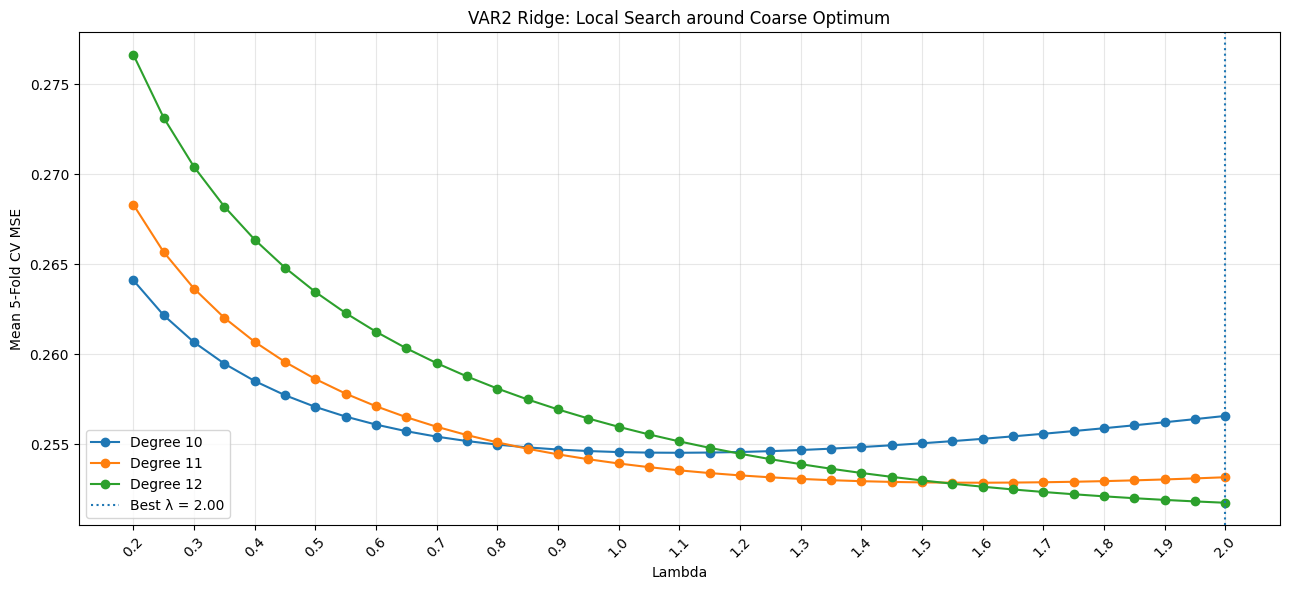

In [ ]:
# ============================================================
# VAR2 — GRANULAR LOCAL RIDGE SEARCH
# Degrees: 10, 11, 12
# Lambda: 0.20 to 2.00, step 0.05
# 5-Fold Cross Validation
# ============================================================

ridge_local_degrees = [10, 11, 12]
ridge_local_lambdas = np.arange(0.20, 2.001, 0.05)

ridge_local_results = []

for degree in ridge_local_degrees:

    for lam in ridge_local_lambdas:

        fold_mse = []
        fold_r2 = []

        for train_idx, val_idx in kf2.split(X2):

            # Split current fold
            X_train = X2.iloc[train_idx]
            X_val = X2.iloc[val_idx]

            y_train = y2.iloc[train_idx]
            y_val = y2.iloc[val_idx]

            # ------------------------------------------------
            # 1. Polynomial features
            # ------------------------------------------------
            poly = PolynomialFeatures(
                degree=degree,
                include_bias=False
            )

            X_train_poly = poly.fit_transform(X_train)
            X_val_poly = poly.transform(X_val)

            # ------------------------------------------------
            # 2. Standardize using training fold ONLY
            # ------------------------------------------------
            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train_poly)
            X_val_scaled = scaler.transform(X_val_poly)

            # ------------------------------------------------
            # 3. Ridge regression
            # ------------------------------------------------
            model = Ridge(alpha=lam)

            model.fit(X_train_scaled, y_train)

            # ------------------------------------------------
            # 4. Predict validation fold
            # ------------------------------------------------
            y_pred = model.predict(X_val_scaled)

            # ------------------------------------------------
            # 5. Evaluate
            # ------------------------------------------------
            fold_mse.append(
                mean_squared_error(y_val, y_pred)
            )

            fold_r2.append(
                r2_score(y_val, y_pred)
            )

        ridge_local_results.append({
            'degree': degree,
            'lambda': lam,
            'mse': np.mean(fold_mse),
            'r2': np.mean(fold_r2)
        })


# ============================================================
# RESULTS
# ============================================================

ridge_local_df = pd.DataFrame(ridge_local_results)

best_ridge_local_mse = ridge_local_df.loc[
    ridge_local_df['mse'].idxmin()
]

best_ridge_local_r2 = ridge_local_df.loc[
    ridge_local_df['r2'].idxmax()
]

print("=== GRANULAR LOCAL RIDGE SEARCH ===")

print("\nBest by MSE:")
print(best_ridge_local_mse)

print("\nBest by R²:")
print(best_ridge_local_r2)

print("\nTop 10 configurations by MSE:")

display(
    ridge_local_df
    .sort_values('mse')
    .head(10)
)


# ============================================================
# PLOT: MSE vs LAMBDA FOR EACH DEGREE
# ============================================================

plt.figure(figsize=(13, 6))

for degree in ridge_local_degrees:

    temp = (
        ridge_local_df[
            ridge_local_df['degree'] == degree
        ]
        .sort_values('lambda')
    )

    plt.plot(
        temp['lambda'],
        temp['mse'],
        'o-',
        label=f'Degree {degree}'
    )


best_degree = int(best_ridge_local_mse['degree'])
best_lambda = best_ridge_local_mse['lambda']

plt.axvline(
    best_lambda,
    linestyle=':',
    label=f'Best λ = {best_lambda:.2f}'
)

plt.xlabel('Lambda')
plt.ylabel('Mean 5-Fold CV MSE')

plt.title(
    'VAR2 Ridge: Local Search around Coarse Optimum'
)

plt.xticks(
    np.arange(0.2, 2.01, 0.1),
    rotation=45
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

=== EXTENDED RIDGE SEARCH ===

Best by MSE:
degree    12.000000
lambda     2.500000
mse        0.251404
r2         0.994409
Name: 43, dtype: float64

Best by R²:
degree    12.000000
lambda     2.500000
mse        0.251404
r2         0.994409
Name: 43, dtype: float64

Top 10:


,degree,lambda,mse,r2
43,12,2.50,0.251404,0.994409
44,12,2.75,0.251453,0.994407
42,12,2.25,0.251488,0.994408
45,12,3.00,0.251608,0.994404
41,12,2.00,0.251742,0.994403
46,12,3.25,0.251851,0.994398
47,12,3.50,0.252166,0.994391
40,12,1.75,0.252215,0.994393
48,12,3.75,0.252542,0.994382
2,11,1.50,0.252875,0.994374


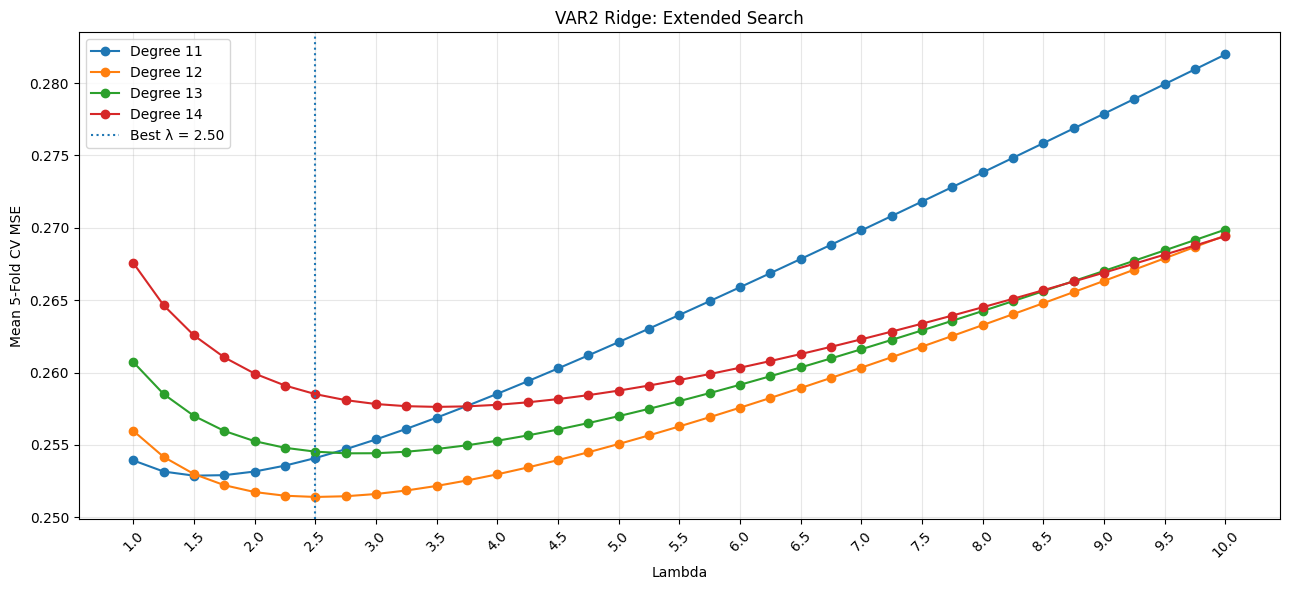

In [ ]:
# ============================================================
# VAR2 — EXTENDED RIDGE SEARCH
# Degrees 11-14
# Lambda 1.0 -> 10.0
# ============================================================

ridge_ext_degrees = [11, 12, 13, 14]
ridge_ext_lambdas = np.arange(1.0, 10.01, 0.25)

ridge_ext_results = []

for degree in ridge_ext_degrees:

    for lam in ridge_ext_lambdas:

        fold_mse = []
        fold_r2 = []

        for train_idx, val_idx in kf2.split(X2):

            X_train = X2.iloc[train_idx]
            X_val = X2.iloc[val_idx]

            y_train = y2.iloc[train_idx]
            y_val = y2.iloc[val_idx]

            # Polynomial features
            poly = PolynomialFeatures(
                degree=degree,
                include_bias=False
            )

            X_train_poly = poly.fit_transform(X_train)
            X_val_poly = poly.transform(X_val)

            # Standardization
            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train_poly)
            X_val_scaled = scaler.transform(X_val_poly)

            # Ridge
            model = Ridge(alpha=lam)
            model.fit(X_train_scaled, y_train)

            # Validation predictions
            y_pred = model.predict(X_val_scaled)

            fold_mse.append(
                mean_squared_error(y_val, y_pred)
            )

            fold_r2.append(
                r2_score(y_val, y_pred)
            )

        ridge_ext_results.append({
            'degree': degree,
            'lambda': lam,
            'mse': np.mean(fold_mse),
            'r2': np.mean(fold_r2)
        })


ridge_ext_df = pd.DataFrame(ridge_ext_results)

best_ridge_ext_mse = ridge_ext_df.loc[
    ridge_ext_df['mse'].idxmin()
]

best_ridge_ext_r2 = ridge_ext_df.loc[
    ridge_ext_df['r2'].idxmax()
]


print("=== EXTENDED RIDGE SEARCH ===")

print("\nBest by MSE:")
print(best_ridge_ext_mse)

print("\nBest by R²:")
print(best_ridge_ext_r2)

print("\nTop 10:")
display(
    ridge_ext_df
    .sort_values('mse')
    .head(10)
)


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(13, 6))

for degree in ridge_ext_degrees:

    temp = (
        ridge_ext_df[
            ridge_ext_df['degree'] == degree
        ]
        .sort_values('lambda')
    )

    plt.plot(
        temp['lambda'],
        temp['mse'],
        'o-',
        label=f'Degree {degree}'
    )

best_lambda = best_ridge_ext_mse['lambda']

plt.axvline(
    best_lambda,
    linestyle=':',
    label=f'Best λ = {best_lambda:.2f}'
)

plt.xlabel('Lambda')
plt.ylabel('Mean 5-Fold CV MSE')

plt.title('VAR2 Ridge: Extended Search')

plt.xticks(np.arange(1, 10.1, 0.5), rotation=45)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

### Finalizing VAR2: Train Best Model on Complete Training Set and Prepare for Testing

In [ ]:
# ============================================================
# VAR2 — TRAIN FINAL RIDGE MODEL ON ALL TRAINING DATA
# ============================================================

best_degree_var2 = 12
best_lambda_var2 = 2.5

# ------------------------------------------------------------
# 1. Generate degree-12 polynomial features
# ------------------------------------------------------------
final_poly_var2 = PolynomialFeatures(
    degree=best_degree_var2,
    include_bias=False
)

X2_poly_all = final_poly_var2.fit_transform(X2)


# ------------------------------------------------------------
# 2. Standardize polynomial features
# Fit scaler on ALL training data
# ------------------------------------------------------------
final_scaler_var2 = StandardScaler()

X2_scaled_all = final_scaler_var2.fit_transform(X2_poly_all)


# ------------------------------------------------------------
# 3. Train final Ridge model on ALL training data
# ------------------------------------------------------------
final_model_var2 = Ridge(
    alpha=best_lambda_var2
)

final_model_var2.fit(X2_scaled_all, y2)


# ------------------------------------------------------------
# 4. Basic information
# ------------------------------------------------------------
print("=== VAR2 FINAL MODEL TRAINING COMPLETE ===")

print(f"Model: Ridge Regression")
print(f"Polynomial degree: {best_degree_var2}")
print(f"Lambda (alpha): {best_lambda_var2}")

print(f"Original features: {X2.shape[1]}")
print(f"Polynomial features generated: {X2_poly_all.shape[1]}")
print(f"Training samples: {X2.shape[0]}")

print(f"Intercept: {final_model_var2.intercept_:.6f}")
print(f"Number of coefficients: {len(final_model_var2.coef_)}")

=== VAR2 FINAL MODEL TRAINING COMPLETE ===
Model: Ridge Regression
Polynomial degree: 12
Lambda (alpha): 2.5
Original features: 3
Polynomial features generated: 454
Training samples: 1000
Intercept: 2.460914
Number of coefficients: 454


In [ ]:
# ============================================================
# VAR2 — TEST PREDICTION AND CSV SUBMISSION
# ============================================================

from google.colab import files

# 1. Load test dataset
test_var2 = pd.read_csv('/content/IMT2024080_test_var2(in).csv')

print("Test shape:", test_var2.shape)
print("Test columns:", test_var2.columns.tolist())

# 2. Select input features in correct order
X2_test = test_var2[X2.columns]

# 3. Apply SAME polynomial transformation
X2_test_poly = final_poly_var2.transform(X2_test)

# 4. Apply SAME fitted scaler
X2_test_scaled = final_scaler_var2.transform(X2_test_poly)

# 5. Predict using the previously trained Ridge model
y2_pred = final_model_var2.predict(X2_test_scaled)

# 6. Create submission DataFrame
submission_var2 = pd.DataFrame({
    'y': y2_pred
})

# 7. Check predictions
print("\n=== VAR2 PREDICTION SUMMARY ===")
print("Prediction shape:", submission_var2.shape)
print("Missing values:", submission_var2.isna().sum().sum())
print("Infinite values:", np.isinf(y2_pred).sum())

display(submission_var2.head(10))

# 8. Save CSV file
output_path = '/content/IMT2024080_pred_var2.csv'

submission_var2.to_csv(output_path, index=False)

print("\nSaved:", output_path)

# 9. Download CSV
files.download(output_path)

Test shape: (1000, 3)
Test columns: ['x1', 'x2', 'x3']

=== VAR2 PREDICTION SUMMARY ===
Prediction shape: (1000, 1)
Missing values: 0
Infinite values: 0


,y
0,-3.931167
1,5.150220
2,8.316955
3,6.782137
4,-0.148628
5,22.179408
6,2.410358
7,-5.324425
8,0.247346
9,3.693021



Saved: /content/IMT2024080_pred_var2.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

=== TRAINING TARGET (y2) STATS ===
count    1000.000000
mean        2.460914
std         6.781684
min       -30.141976
25%        -0.570387
50%         1.240816
75%         5.460330
max        39.026721
Name: y, dtype: float64

=== TEST PREDICTIONS (y2_pred) STATS ===
count    1000.000000
mean        2.155006
std         6.546888
min       -29.617886
25%        -0.606436
50%         0.990184
75%         4.922425
max        33.791782
Name: y, dtype: float64

NaNs in predictions: 0
Infs in predictions: 0


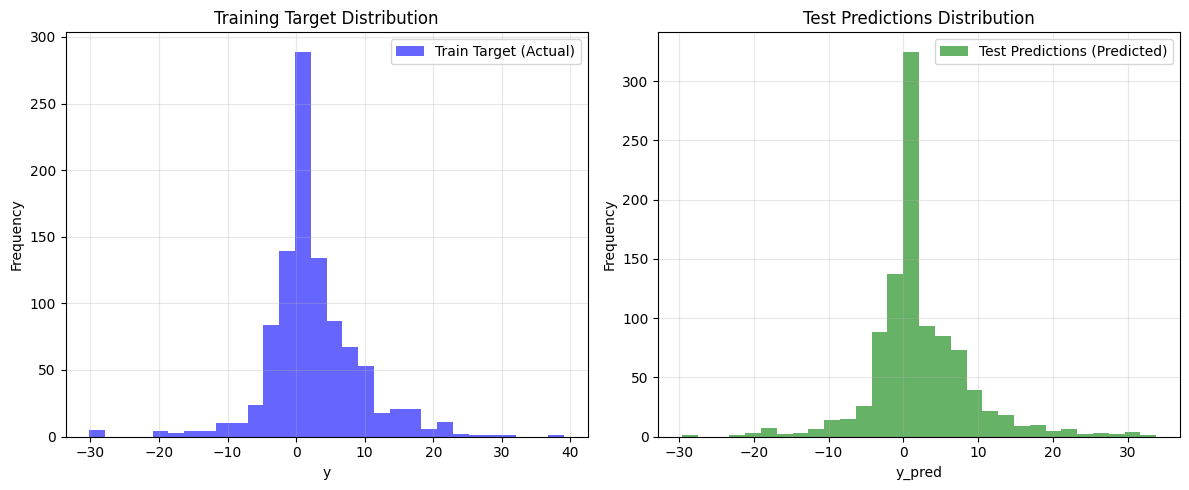

In [ ]:
# ============================================================
# DIAGNOSTIC SANITY CHECK FOR VAR2 TEST PREDICTIONS
# ============================================================

print("=== TRAINING TARGET (y2) STATS ===")
print(y2.describe())

print("\n=== TEST PREDICTIONS (y2_pred) STATS ===")
print(submission_var2['y'].describe())

# 1. Check for basic anomalies
nan_count = submission_var2['y'].isna().sum()
inf_count = np.isinf(submission_var2['y']).sum()
print(f"\nNaNs in predictions: {nan_count}")
print(f"Infs in predictions: {inf_count}")

# 2. Plot distributions to visually check alignment
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(y2, bins=30, color='blue', alpha=0.6, label='Train Target (Actual)')
plt.title('Training Target Distribution')
plt.xlabel('y')
plt.ylabel('Frequency')
plt.grid(alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(submission_var2['y'], bins=30, color='green', alpha=0.6, label='Test Predictions (Predicted)')
plt.title('Test Predictions Distribution')
plt.xlabel('y_pred')
plt.ylabel('Frequency')
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# VAR2 — ELASTIC NET 5-FOLD CROSS VALIDATION
# Coarse hyperparameter search
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# Hyperparameters
degrees = [10, 11, 12, 13, 14]
alphas = [0.0001, 0.001, 0.01, 0.1, 1]
l1_ratios = [0.1, 0.25, 0.5, 0.75, 0.9]

elastic_results = []

# Reuse existing VAR2 data: X2, y2, kf2

for degree in degrees:

    print(f"Processing degree {degree}...", flush=True)

    # Cache transformed folds for this degree
    fold_data = []

    for train_idx, val_idx in kf2.split(X2):

        X_train = X2.iloc[train_idx]
        X_val = X2.iloc[val_idx]

        y_train = y2.iloc[train_idx]
        y_val = y2.iloc[val_idx]

        # 1. Polynomial features
        poly = PolynomialFeatures(
            degree=degree,
            include_bias=False
        )

        X_train_poly = poly.fit_transform(X_train)
        X_val_poly = poly.transform(X_val)

        # 2. Standardization (training fold only)
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train_poly)
        X_val_scaled = scaler.transform(X_val_poly)

        fold_data.append((
            X_train_scaled,
            X_val_scaled,
            y_train,
            y_val
        ))

    # 3. Hyperparameter combinations
    for alpha in alphas:

        for ratio in l1_ratios:

            fold_mse = []
            fold_r2 = []
            fold_iters = []
            warning_count = 0

            for X_tr, X_val, y_tr, y_val in fold_data:

                model = ElasticNet(
                    alpha=alpha,
                    l1_ratio=ratio,
                    max_iter=30000,
                    tol=1e-5,
                    selection='cyclic'
                )

                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter(
                        "always", ConvergenceWarning
                    )
                    model.fit(X_tr, y_tr)

                warning_count += sum(
                    issubclass(w.category, ConvergenceWarning)
                    for w in caught
                )

                y_pred = model.predict(X_val)

                fold_mse.append(
                    mean_squared_error(y_val, y_pred)
                )

                fold_r2.append(
                    r2_score(y_val, y_pred)
                )

                fold_iters.append(model.n_iter_)

            elastic_results.append({
                'degree': degree,
                'alpha': alpha,
                'l1_ratio': ratio,
                'mse': np.mean(fold_mse),
                'r2': np.mean(fold_r2),
                'max_iterations': max(fold_iters),
                'warnings': warning_count
            })

# ============================================================
# RESULTS
# ============================================================

elastic_df = pd.DataFrame(elastic_results)

print("\n=== BEST ELASTIC NET BY MSE ===")
best_elastic_mse = elastic_df.loc[
    elastic_df['mse'].idxmin()
]
print(best_elastic_mse)

print("\n=== BEST ELASTIC NET BY R² ===")
best_elastic_r2 = elastic_df.loc[
    elastic_df['r2'].idxmax()
]
print(best_elastic_r2)

print("\n=== TOP 10 CONFIGURATIONS ===")
display(
    elastic_df.sort_values('mse').head(10)
)

print("\n=== CONVERGENCE CHECK ===")
print(
    "Configurations with warnings:",
    (elastic_df['warnings'] > 0).sum()
)

Processing degree 10...
Processing degree 11...
Processing degree 12...
Processing degree 13...
Processing degree 14...

=== BEST ELASTIC NET BY MSE ===
degree               11.000000
alpha                 0.001000
l1_ratio              0.250000
mse                   0.253192
r2                    0.994364
max_iterations    30000.000000
warnings              5.000000
Name: 31, dtype: float64

=== BEST ELASTIC NET BY R² ===
degree               11.000000
alpha                 0.001000
l1_ratio              0.250000
mse                   0.253192
r2                    0.994364
max_iterations    30000.000000
warnings              5.000000
Name: 31, dtype: float64

=== TOP 10 CONFIGURATIONS ===


,degree,alpha,l1_ratio,mse,r2,max_iterations,warnings
31,11,0.001,0.25,0.253192,0.994364,30000,5
32,11,0.001,0.50,0.253225,0.994360,30000,5
33,11,0.001,0.75,0.253581,0.994351,27876,0
58,12,0.001,0.75,0.253618,0.994354,27915,0
57,12,0.001,0.50,0.253667,0.994355,30000,5
30,11,0.001,0.10,0.254029,0.994348,30000,5
56,12,0.001,0.25,0.254080,0.994351,30000,5
6,10,0.001,0.25,0.254548,0.994333,30000,4
82,13,0.001,0.50,0.254552,0.994337,30000,3
34,11,0.001,0.90,0.254576,0.994328,24023,0



=== CONVERGENCE CHECK ===
Configurations with warnings: 44
